Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cpu

STEP 1 — DATA PREPARATION
[AEP] raw rows=121273, unit=MW, sorted=False, duplicated timestamps=4
[AEP] missing hours after regularising the hourly grid: 27 (0.022%) -> time-interpolated (max gap 6 h)
[AEP] feature table (120960, 17), 2004-10-15 01:00:00 -> 2018-08-03 00:00:00; target y = AEP_MW at t (24 h ahead)
[PV] raw rows=3546, columns=['Ppv_actual', 'Qpv_actual', 'Pload_actual', 'Qload_actual'] (Ppv/Pload=active power, Qpv/Qload=reactive power; units not documented -> treated as kW/kvar)
[PV] median sampling step=0 days 00:00:20, largest gap=0 days 01:18:15, NaNs=0
[PV] after 1-min resampling: 1440 rows, empty minutes=6.39% -> time-interpolated
[PV] NOTE: the file covers a single day -> a chronological split cannot contain a full diurnal cycle in every part (see limitations).
[PV] feature table (1350, 17); target y = Ppv at t, all inputs from

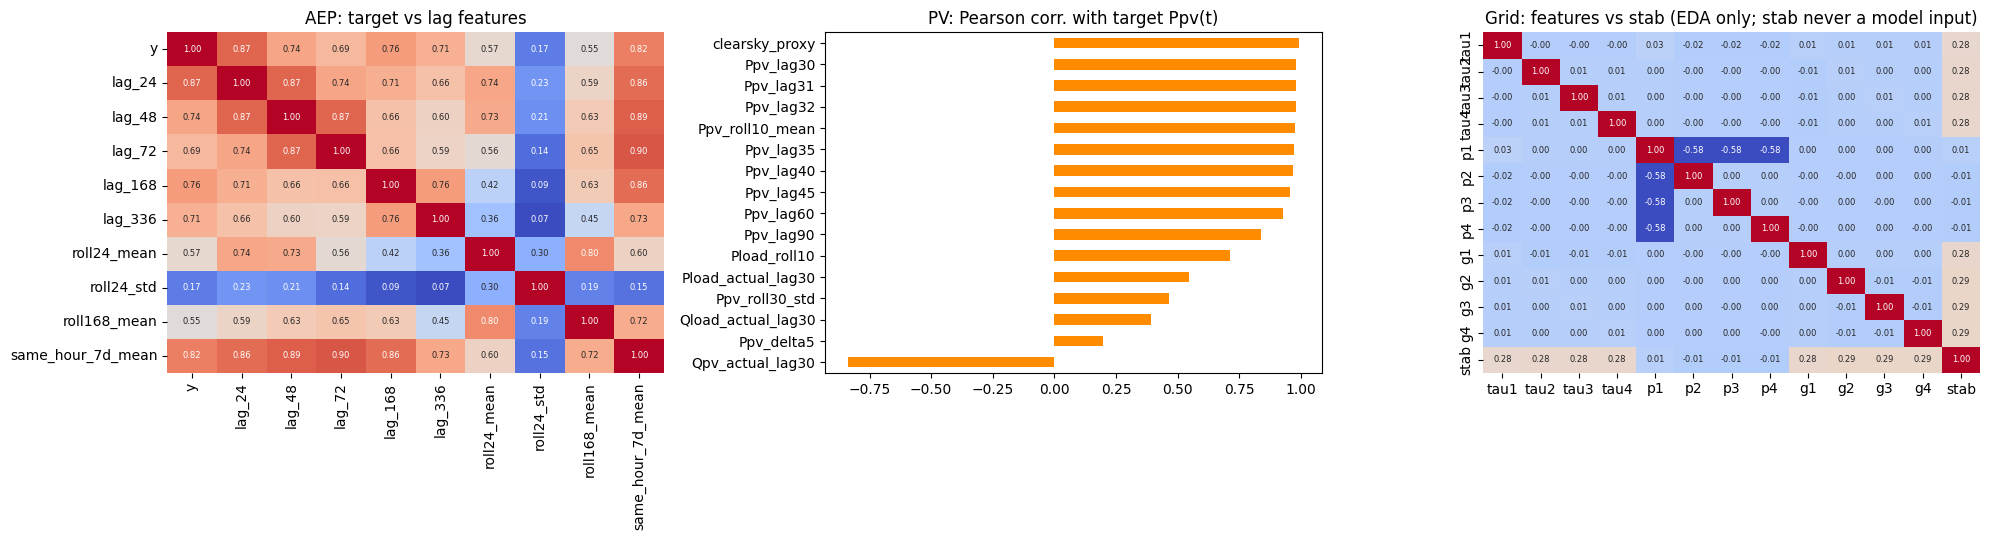

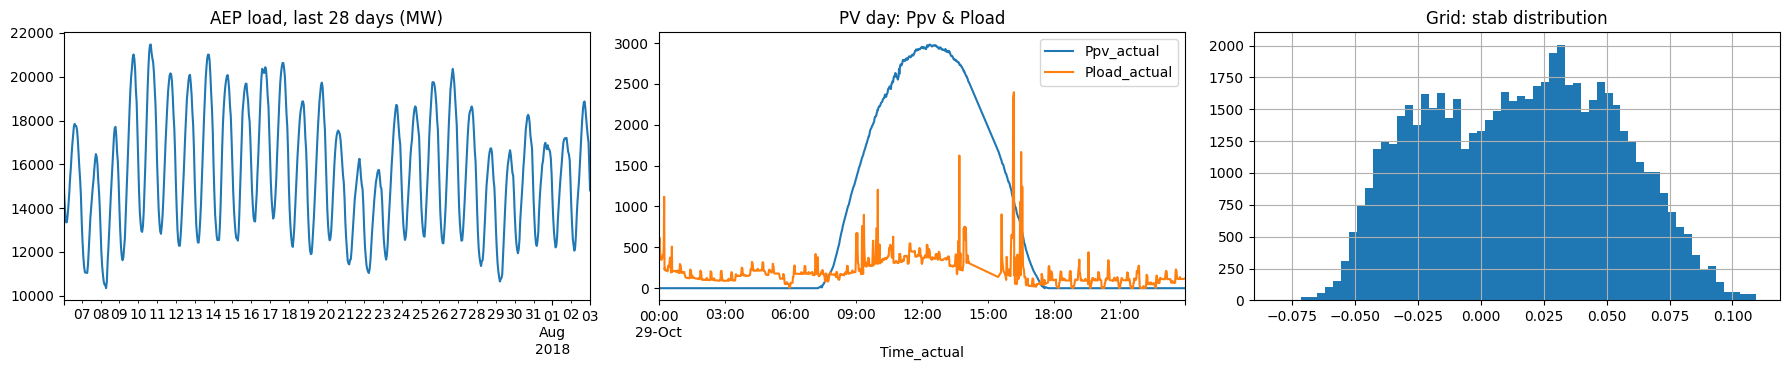

[aep] chronological split: train 84672 (2004-10-15 01:00:00→2014-06-13 00:00:00) | val 18144 | test 18144 (2016-07-08 01:00:00→2018-08-03 00:00:00)
[pv] chronological split: train 675 (2021-10-29 01:30:00→2021-10-29 12:44:00) | val 202 | test 473 (2021-10-29 16:07:00→2021-10-29 23:59:00)
[GRID] stratified random split 70/15/15 (no temporal axis): 42000/9000/9000

STEP 2 — PERSISTENCE / RANDOM FOREST / XGBOOST / LOGISTIC REGRESSION

--- aep | step2_baselines (mean [95% CI]) ---
metric                                MAE                      R2               RMSE
method       setting                                                                
Persistence  central    926 [891.3,967.3]  0.7584 [0.7338,0.7793]   1221 [1172,1274]
RandomForest central  705.5 [677.6,734.9]  0.8591 [0.8468,0.8692]  933 [897.5,969.9]
XGBoost      central  714.9 [683.6,741.6]  0.8592 [0.8473,0.8717]  932.6 [890,967.7]

--- pv | step2_baselines (mean [95% CI]) ---
metric                                MAE      

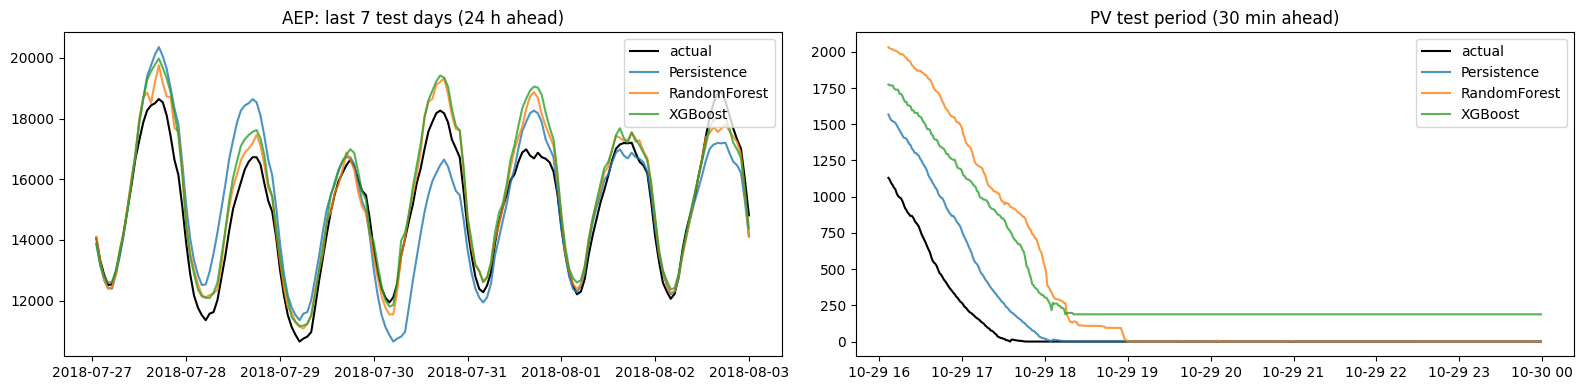

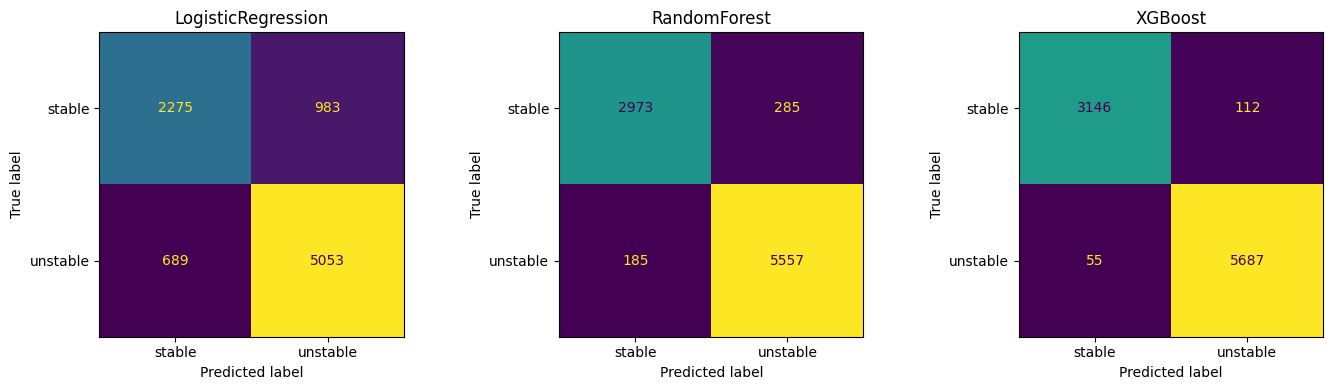


STEP 3 — FEDERATED LEARNING

>>> Main comparison on aep (5 seeds, 5 clients, non-IID Dirichlet alpha=0.5)

--- aep | step3_main (mean [95% CI]) ---
metric                                    MAE                      R2                 RMSE
method     setting                                                                        
Central-NN K=5,alpha=0.5  743.4 [722.2,764.6]   0.8467 [0.8385,0.855]  972.8 [946.5,999.1]
FedAvg     K=5,alpha=0.5    757.6 [712.2,803]  0.8485 [0.8357,0.8613]     967 [926.7,1007]
Local-only K=5,alpha=0.5  852.5 [779.9,925.1]  0.8046 [0.7744,0.8348]     1094 [1010,1178]
   heterogeneity index (JSD) = 0.390 | rounds to ≤5% of central: 5 | FedAvg comm: 4.25 MB vs raw-data upload 5.76 MB


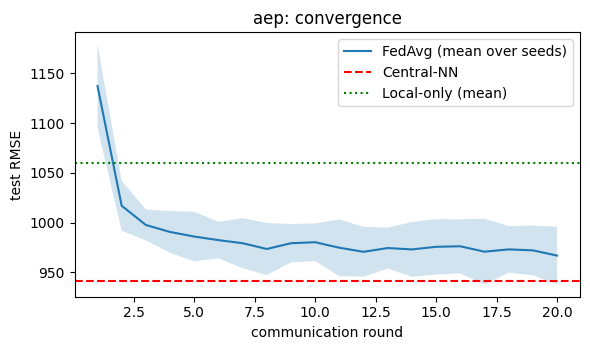


>>> Main comparison on pv (5 seeds, 5 clients, non-IID Dirichlet alpha=0.5)

--- pv | step3_main (mean [95% CI]) ---
metric                                    MAE                      R2                 RMSE
method     setting                                                                        
Central-NN K=5,alpha=0.5  247.1 [212.5,281.7]  -3.521 [-4.846,-2.196]    497 [423.5,570.5]
FedAvg     K=5,alpha=0.5    243 [213.2,272.8]  -2.888 [-3.718,-2.058]  462.1 [413.2,511.1]
Local-only K=5,alpha=0.5    229 [134.2,323.7]  -2.59 [-4.614,-0.5646]  415.1 [332.8,497.4]
   heterogeneity index (JSD) = 0.210 | rounds to ≤5% of central: 1 | FedAvg comm: 6.38 MB vs raw-data upload 0.05 MB


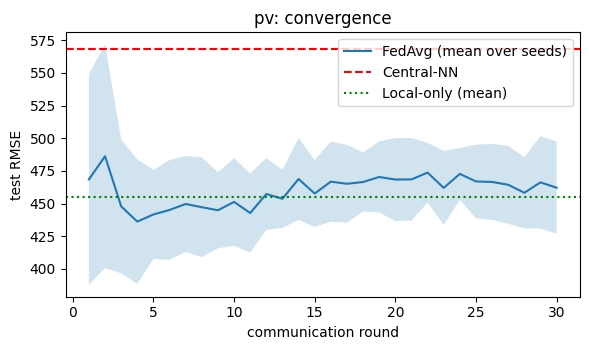


>>> Main comparison on grid (5 seeds, 5 clients, non-IID Dirichlet alpha=0.5)

--- grid | step3_main (mean [95% CI]) ---
metric                                        F1                  PR_AUC               Precision                 ROC_AUC                  Recall
method     setting                                                                                                                              
Central-NN K=5,alpha=0.5  0.9816 [0.9804,0.9828]  0.9988 [0.9988,0.9989]  0.9814 [0.9765,0.9862]  0.9979 [0.9977,0.9981]  0.9819 [0.9764,0.9873]
FedAvg     K=5,alpha=0.5   0.9754 [0.971,0.9799]  0.9981 [0.9978,0.9985]  0.9699 [0.9566,0.9831]   0.9966 [0.996,0.9973]   0.9811 [0.9763,0.986]
Local-only K=5,alpha=0.5  0.8261 [0.7391,0.9131]  0.9797 [0.9727,0.9867]   0.8744 [0.754,0.9949]  0.9658 [0.9547,0.9768]  0.8084 [0.7092,0.9076]
   heterogeneity index (JSD) = 0.209 | rounds to ≤5% of central: 1 | FedAvg comm: 5.06 MB vs raw-data upload 2.18 MB


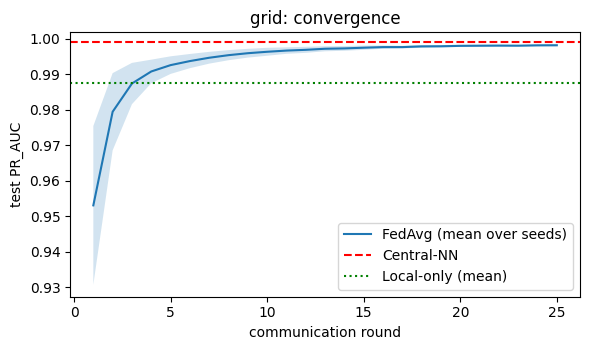


>>> Step 3/6: client-count and non-IID sweeps (FedAvg vs local-only)

--- aep: RMSE across partitions (central-NN ref = 972.8) ---
method                    FedAvg  Local-only
setting                                     
dirichlet(a=0.1),K=5   1202.6034   1501.5593
dirichlet(a=0.3),K=5   1056.0677   1291.5871
dirichlet(a=0.5),K=10   983.2902   1119.8674
dirichlet(a=0.5),K=3    972.0037   1070.3434
dirichlet(a=1.0),K=5    936.7997    985.8587
iid,K=5                 930.8046    938.9758
temporal,K=5            977.7219   1108.5915

--- pv: RMSE across partitions (central-NN ref = 497) ---
method                   FedAvg  Local-only
setting                                    
dirichlet(a=0.1),K=5   376.9084    714.4125
dirichlet(a=0.3),K=5   362.2873    415.8754
dirichlet(a=0.5),K=10  376.1800    397.4332
dirichlet(a=0.5),K=3   410.6612    435.7221
dirichlet(a=1.0),K=5   414.2666    412.1382
iid,K=5                395.4605    400.2249
temporal,K=5           367.1202    555.4210

--- gri

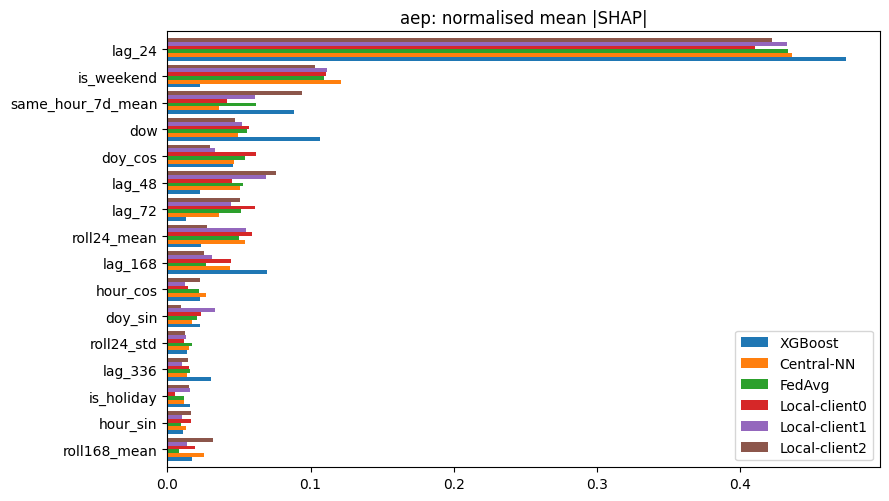

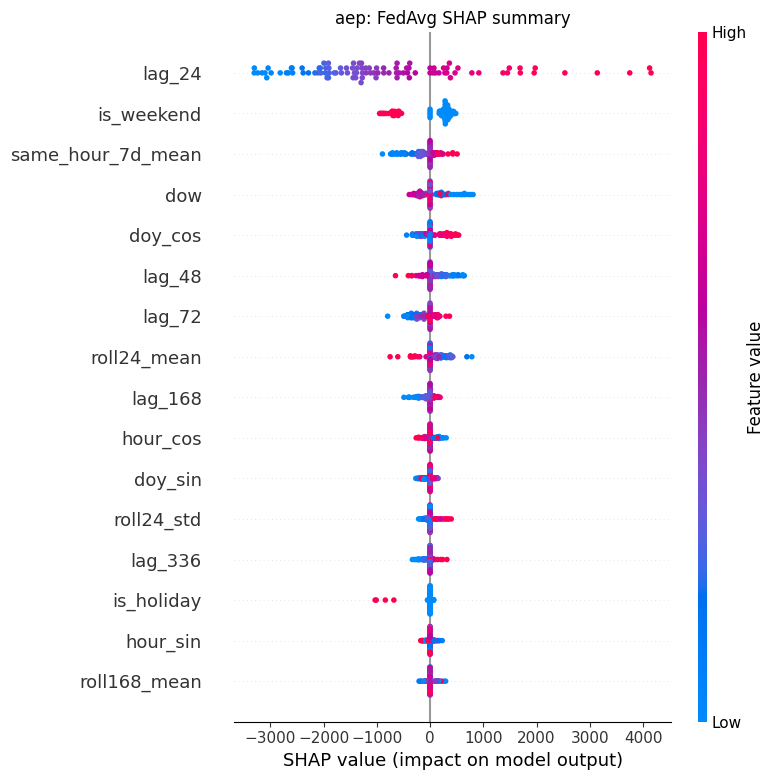


[pv] normalised mean|SHAP| (top 10 by FedAvg):
                XGBoost  Central-NN  FedAvg  Local-client0  Local-client1  Local-client2
clearsky_proxy    0.012       0.155   0.167          0.089          0.135          0.040
Ppv_roll30_std    0.000       0.135   0.130          0.175          0.176          0.129
Ppv_lag40         0.003       0.118   0.120          0.007          0.089          0.012
Ppv_lag35         0.005       0.098   0.115          0.083          0.072          0.013
Ppv_lag45         0.004       0.096   0.094          0.053          0.088          0.062
Ppv_lag31         0.243       0.090   0.076          0.094          0.001          0.121
Ppv_lag32         0.006       0.052   0.068          0.100          0.065          0.113
Ppv_lag90         0.002       0.057   0.064          0.049          0.058          0.098
Ppv_delta5        0.000       0.046   0.062          0.066          0.012          0.124
Ppv_lag60         0.000       0.054   0.038          0.002    

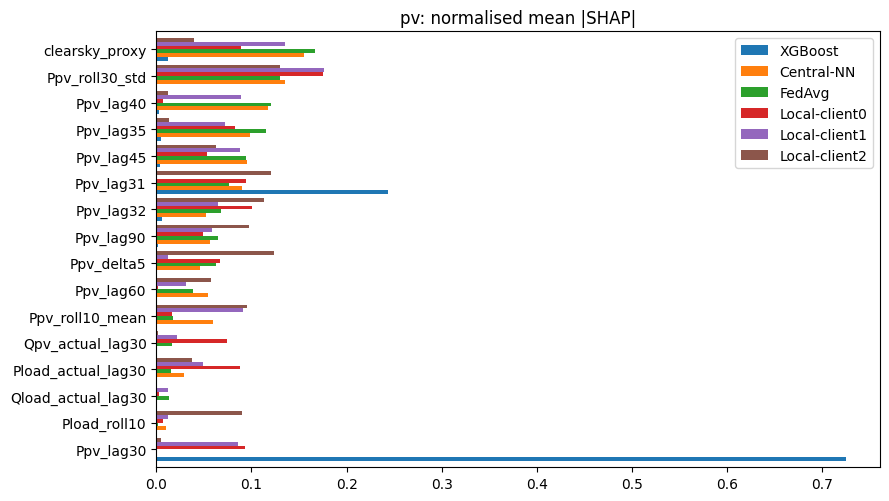

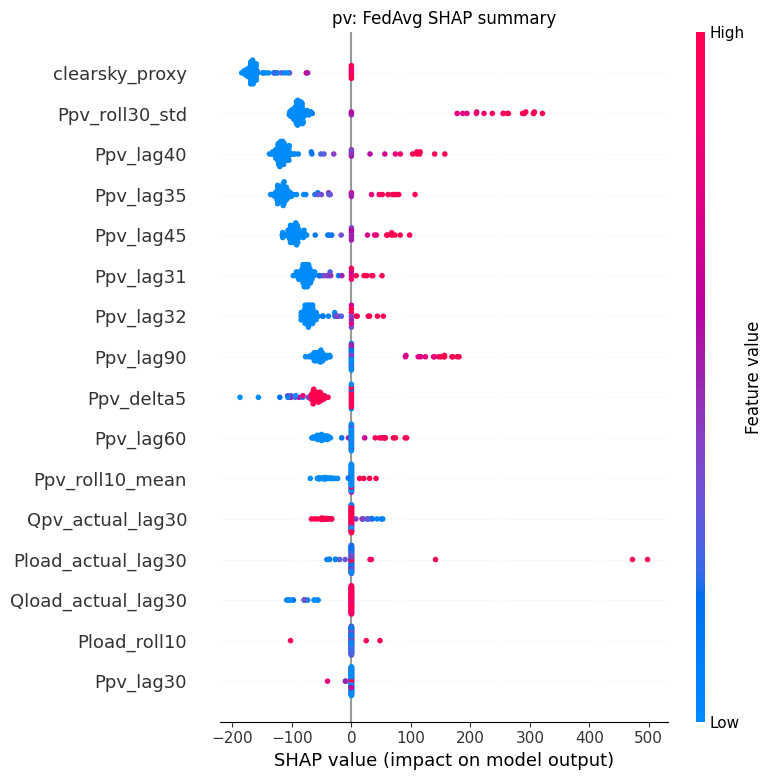


[grid] normalised mean|SHAP| (top 10 by FedAvg):
      XGBoost  Central-NN  FedAvg  Local-client0  Local-client1  Local-client2
tau1    0.149       0.136   0.140          0.141          0.148          0.138
g2      0.118       0.120   0.119          0.115          0.113          0.124
g4      0.122       0.128   0.119          0.108          0.105          0.125
tau2    0.133       0.124   0.116          0.124          0.123          0.118
tau3    0.131       0.118   0.113          0.122          0.119          0.113
g3      0.107       0.102   0.102          0.095          0.079          0.105
tau4    0.128       0.101   0.102          0.108          0.096          0.106
g1      0.099       0.090   0.087          0.091          0.082          0.086
p1      0.007       0.025   0.034          0.039          0.051          0.025
p3      0.002       0.020   0.024          0.021          0.029          0.023
   explanation consistency: {'spearman_Fed_vs_Central': 0.972, 'spearman_Fed_vs_X

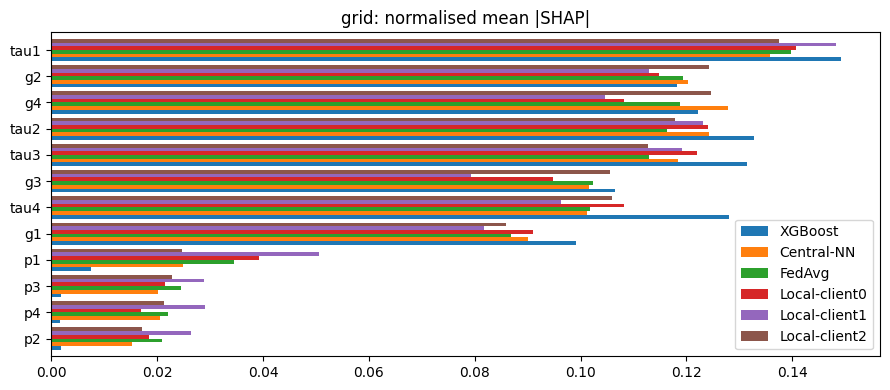

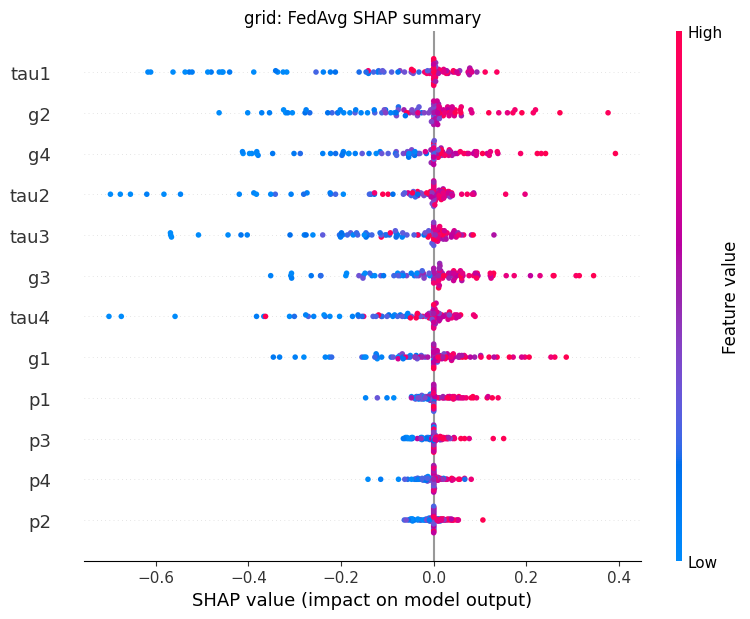


NOTE: SHAP values describe how the trained MODEL uses its inputs (predictive attribution), NOT causal effects on the grid.
      Correlated features (e.g. lag_24/lag_48, p1 = -(p2+p3+p4)) share credit, so rankings can differ between models without implying causal differences.

[aep] Full framework keeps 10/16 SHAP-selected features: ['lag_24', 'lag_48', 'lag_72', 'lag_168', 'roll24_mean', 'same_hour_7d_mean', 'hour_cos', 'doy_cos', 'dow', 'is_weekend']

--- aep | step3_main (mean [95% CI]) ---
metric                                                  MAE                      R2                 RMSE
method                   setting                                                                        
Central-NN               K=5,alpha=0.5  743.4 [722.2,764.6]   0.8467 [0.8385,0.855]  972.8 [946.5,999.1]
FedAvg                   K=5,alpha=0.5    757.6 [712.2,803]  0.8485 [0.8357,0.8613]     967 [926.7,1007]
Full(SHAP-pruned FedAvg) K=5,alpha=0.5    749.8 [715,784.7]  0.8493 [0.8402,0.85

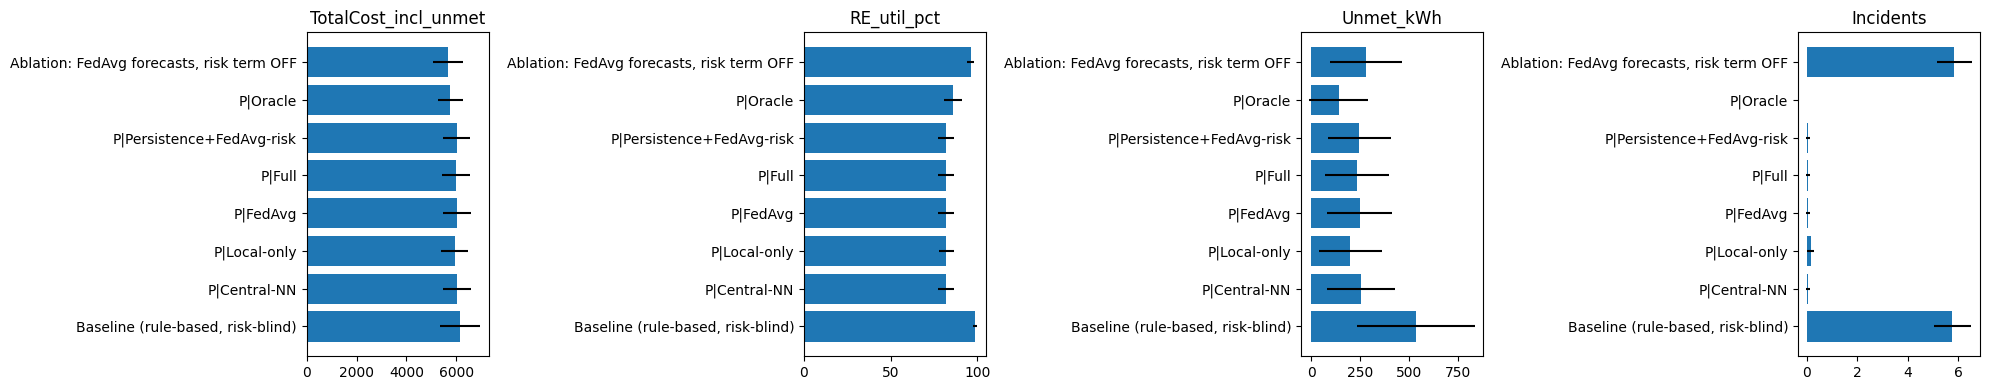


STEP 6 — ABLATION AND ROBUSTNESS

--- aep: RMSE vs missing-value rate ---
method       Central-NN     FedAvg  XGBoost(native NaN)
setting                                                
missing=0%     967.7586   956.8039             944.3793
missing=10%   1021.3848  1053.2619             996.0070
missing=30%   1133.9470  1178.2399            1103.3215

--- pv: RMSE vs missing-value rate ---
method       Central-NN    FedAvg  XGBoost(native NaN)
setting                                               
missing=0%     449.3907  467.1733             410.7770
missing=10%    696.3584  697.9720             638.2705
missing=30%    700.1968  733.9060             776.6511

--- grid: PR_AUC vs missing-value rate ---
method       Central-NN  FedAvg  XGBoost(native NaN)
setting                                             
missing=0%       0.9990  0.9985               0.9980
missing=10%      0.9667  0.9672               0.9795
missing=30%      0.9100  0.9114               0.9343

--- grid: class imba

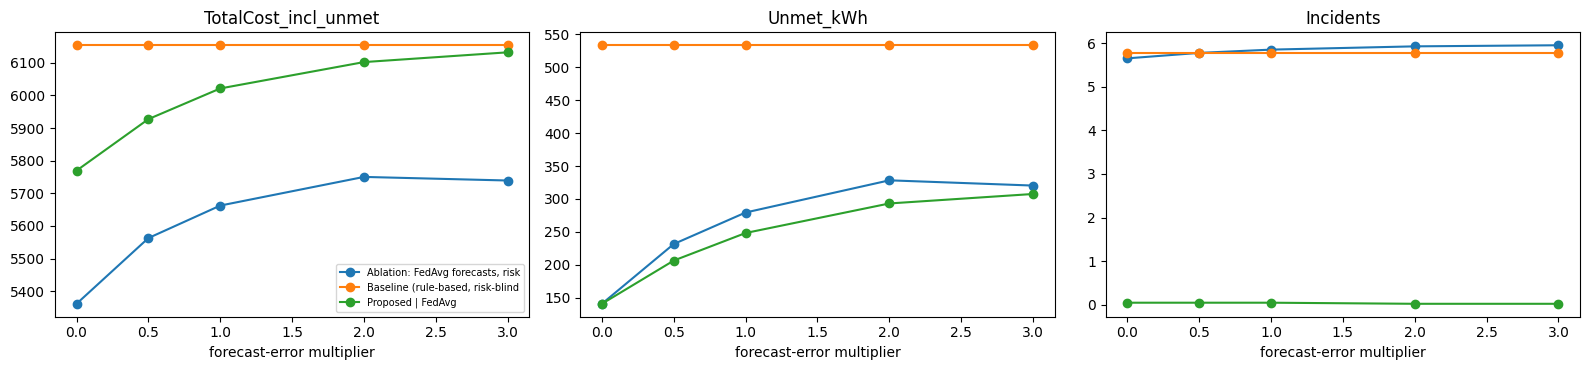


--- Consolidated ablation (seed-averaged forecasting/classification, simulation means) ---
arm                 Centralized NN  Local-only    FedAvg  Full framework (FedAvg+SHAP-pruning+risk-aware opt.)
AEP RMSE (MW)              972.796    1093.989   966.955                                               964.576
PV RMSE (kW)               496.972     415.124   462.128                                               435.200
Grid PR-AUC                  0.999       0.980     0.998                                                 0.999
Grid F1                      0.982       0.826     0.975                                                 0.980
Comm AEP (MB)                5.758       0.000     4.250                                                 3.943
Comm PV (MB)                 0.046       0.000     6.376                                                 5.915
Comm Grid (MB)               2.184       0.000     5.057                                                 4.801
Sim total cost ($)  

In [ ]:
# =============================================================================
# Federated Explainable Intelligence for Renewable-Aware Smart Grid Management
# Energy Forecasting, Stability Assessment, and Adaptive Optimization
# ONE Colab cell. Put the 3 CSVs in DRIVE_DIR (Google Drive), then Run all.
# =============================================================================

# ----------------------------- 0. SETUP / CONFIG -----------------------------
import os, sys, time, math, json, glob, copy, random, warnings, subprocess, contextlib
warnings.filterwarnings('ignore')

def _ensure(mod, pip_name=None):
    try: __import__(mod)
    except ImportError: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name or mod])
for _m in ['shap', 'xgboost', 'scipy', 'seaborn']: _ensure(_m)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, shap, xgboost as xgb
from scipy import stats
from scipy.optimize import linprog
from scipy.spatial.distance import jensenshannon
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, precision_score, recall_score,
                             f1_score, average_precision_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from pandas.tseries.holiday import USFederalHolidayCalendar

try:
    from google.colab import drive
    drive.mount('/content/drive'); IN_COLAB = True
except Exception:
    IN_COLAB = False

# ---- paths: edit DRIVE_DIR only -------------------------------------------------
DRIVE_DIR = '/content/drive/MyDrive/Federated Explainable Intelligence for Renewable-Aware Smart Grid Management: Energy Forecasting, Stability Assessment, and Adaptive Optimization'          # folder that holds the 3 CSVs
FILES = dict(aep='/content/drive/MyDrive/Federated Explainable Intelligence for Renewable-Aware Smart Grid Management: Energy Forecasting, Stability Assessment, and Adaptive Optimization/AEP_hourly.csv', pv='/content/drive/MyDrive/Federated Explainable Intelligence for Renewable-Aware Smart Grid Management: Energy Forecasting, Stability Assessment, and Adaptive Optimization/Load_Demand.csv', grid='/content/drive/MyDrive/Federated Explainable Intelligence for Renewable-Aware Smart Grid Management: Energy Forecasting, Stability Assessment, and Adaptive Optimization/smart_grid_stability_augmented.csv')
OUT_DIR = os.path.join(DRIVE_DIR, 'results'); os.makedirs(os.path.join(OUT_DIR, 'figs'), exist_ok=True)

# ---- experiment settings -------------------------------------------------------
FAST_MODE   = False          # True = quick smoke test (few seeds/rounds/trees)
SEED        = 42
N_SEEDS     = 2 if FAST_MODE else 5        # seeds for main comparison (CI = t-interval over seeds)
N_SEEDS_SW  = 1 if FAST_MODE else 3        # seeds for robustness sweeps
RF_TREES    = 40 if FAST_MODE else 200
PV_H        = 30             # PV forecast horizon (minutes ahead, 1-min resampled data)
SUNRISE, SUNSET = 420, 1050  # approx. local sunrise/sunset minute-of-day for 29 Oct (assumption; used for clear-sky proxy)
N_CLIENTS   = 5
TASK_CFG = {  # rounds, local epochs, lr, batch
    'aep':  dict(rounds=4 if FAST_MODE else 20, E=2, lr=1e-3, bs=512),
    'pv':   dict(rounds=4 if FAST_MODE else 30, E=2, lr=2e-3, bs=64),
    'grid': dict(rounds=4 if FAST_MODE else 25, E=2, lr=2e-3, bs=256)}
XAI_ROWS, XAI_NSAMP, XAI_BG = (25, 60, 10) if FAST_MODE else (100, 150, 20)
SIM_DAYS = 6 if FAST_MODE else 40
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEV)

def find_file(fname):
    roots = [DRIVE_DIR, '/content/drive/MyDrive', '/mnt/user-data/uploads']
    for r in roots:
        if os.path.isdir(r):
            hits = glob.glob(os.path.join(r, '**', fname), recursive=True)
            if hits: return hits[0]
    raise FileNotFoundError(f'{fname} not found. Put it in {DRIVE_DIR}')

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

COST, ROWS = [], []   # computational-cost log, long-format results log
@contextlib.contextmanager
def timer(stage, **kw):
    t = time.time(); yield
    COST.append(dict(stage=stage, seconds=round(time.time() - t, 2), **kw))

def mean_ci(v):
    v = np.asarray(v, float); m = v.mean()
    if len(v) < 2: return m, np.nan, np.nan
    h = stats.t.ppf(.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v)); return m, m - h, m + h

def log(task, exp, method, setting, metric, mean, lo=np.nan, hi=np.nan, n=1):
    ROWS.append(dict(task=task, experiment=exp, method=method, setting=setting, metric=metric, mean=mean, ci_lo=lo, ci_hi=hi, n=n))

def log_runs(task, exp, method, setting, list_of_metric_dicts):
    for k in list_of_metric_dicts[0]:
        m, lo, hi = mean_ci([d[k] for d in list_of_metric_dicts]); log(task, exp, method, setting, k, m, lo, hi, len(list_of_metric_dicts))

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'figs', name + '.png'), dpi=130); plt.show()

def reg_metrics(y, p):
    return dict(MAE=mean_absolute_error(y, p), RMSE=float(np.sqrt(mean_squared_error(y, p))), R2=r2_score(y, p))

def clf_metrics(y, prob, thr=.5):
    pr = (prob >= thr).astype(int)
    try: roc = roc_auc_score(y, prob)
    except Exception: roc = np.nan
    return dict(Precision=precision_score(y, pr, zero_division=0), Recall=recall_score(y, pr, zero_division=0),
                F1=f1_score(y, pr, zero_division=0), PR_AUC=average_precision_score(y, prob), ROC_AUC=roc)

def boot_ci(y, p, fn, block=1, nb=200, seed=0):
    """(moving-block) bootstrap 95% CI of every metric returned by fn."""
    rng = np.random.default_rng(seed); n = len(y); nblk = int(np.ceil(n / block)); acc = {}
    for _ in range(nb):
        st = rng.integers(0, max(n - block, 1), nblk)
        idx = np.clip((st[:, None] + np.arange(block)).ravel()[:n], 0, n - 1)
        for k, v in fn(y[idx], p[idx]).items(): acc.setdefault(k, []).append(v)
    return {k: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5)) for k, v in acc.items()}

def log_point(task, exp, method, setting, y, p, kind, block=1):
    fn = reg_metrics if kind == 'reg' else clf_metrics
    m = fn(y, p); ci = boot_ci(y, p, fn, block=block, nb=100 if FAST_MODE else 200)
    for k, v in m.items(): log(task, exp, method, setting, k, v, ci[k][0], ci[k][1], 1)
    return m

# =============================================================================
# STEP 1 — PREPARE THE THREE DATASETS (kept strictly separate)
# =============================================================================
print('\n' + '=' * 78 + '\nSTEP 1 — DATA PREPARATION\n' + '=' * 78)

# ---------- 1a. AEP hourly load (MW): day-ahead (24 h) load forecasting ----------
raw = pd.read_csv(find_file(FILES['aep'])); raw['Datetime'] = pd.to_datetime(raw['Datetime'])
print(f"[AEP] raw rows={len(raw)}, unit=MW, sorted={raw.Datetime.is_monotonic_increasing}, duplicated timestamps={raw.Datetime.duplicated().sum()}")
s = raw.sort_values('Datetime').groupby('Datetime')['AEP_MW'].mean()
s[s <= 0] = np.nan
full = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq='h'))
print(f"[AEP] missing hours after regularising the hourly grid: {full.isna().sum()} ({full.isna().mean():.3%}) -> time-interpolated (max gap 6 h)")
aep_series = full.interpolate('time', limit=6)

def aep_features(s):
    d = pd.DataFrame({'y': s})
    for L in [24, 48, 72, 168, 336]: d[f'lag_{L}'] = s.shift(L)      # all lags >= 24 h => no leakage at 24 h horizon
    sh = s.shift(24)
    d['roll24_mean'] = sh.rolling(24).mean(); d['roll24_std'] = sh.rolling(24).std(); d['roll168_mean'] = sh.rolling(168).mean()
    d['same_hour_7d_mean'] = pd.concat([s.shift(24 * k) for k in range(1, 8)], axis=1).mean(axis=1)
    i = d.index
    d['hour_sin'] = np.sin(2 * np.pi * i.hour / 24); d['hour_cos'] = np.cos(2 * np.pi * i.hour / 24)
    d['doy_sin'] = np.sin(2 * np.pi * i.dayofyear / 365.25); d['doy_cos'] = np.cos(2 * np.pi * i.dayofyear / 365.25)
    d['dow'] = i.dayofweek; d['is_weekend'] = (i.dayofweek >= 5).astype(int)
    hol = USFederalHolidayCalendar().holidays(i.min(), i.max()); d['is_holiday'] = i.normalize().isin(hol).astype(int)
    return d.dropna()
aep = aep_features(aep_series)
print(f"[AEP] feature table {aep.shape}, {aep.index.min()} -> {aep.index.max()}; target y = AEP_MW at t (24 h ahead)")

# ---------- 1b. PV + load (one day, ~20 s sampling): 30-min-ahead solar forecasting ----------
pr = pd.read_csv(find_file(FILES['pv']), parse_dates=['Time_actual']).set_index('Time_actual').sort_index()
pr = pr[~pr.index.duplicated()]
print(f"[PV] raw rows={len(pr)}, columns={list(pr.columns)} (Ppv/Pload=active power, Qpv/Qload=reactive power; units not documented -> treated as kW/kvar)")
print(f"[PV] median sampling step={pr.index.to_series().diff().median()}, largest gap={pr.index.to_series().diff().max()}, NaNs={int(pr.isna().sum().sum())}")
pvm = pr.resample('1min').mean()
print(f"[PV] after 1-min resampling: {len(pvm)} rows, empty minutes={pvm.isna().any(axis=1).mean():.2%} -> time-interpolated")
pvm = pvm.interpolate('time', limit_direction='both'); pvm['Ppv_actual'] = pvm['Ppv_actual'].clip(lower=0)
print('[PV] NOTE: the file covers a single day -> a chronological split cannot contain a full diurnal cycle in every part (see limitations).')

def pv_features(m, H):
    d = pd.DataFrame({'y': m['Ppv_actual']}); P = m['Ppv_actual']
    for k in [0, 1, 2, 5, 10, 15, 30, 60]: d[f'Ppv_lag{H + k}'] = P.shift(H + k)
    sh = P.shift(H)
    d['Ppv_roll10_mean'] = sh.rolling(10).mean(); d['Ppv_roll30_std'] = sh.rolling(30).std(); d['Ppv_delta5'] = sh - P.shift(H + 5)
    for c in ['Pload_actual', 'Qload_actual', 'Qpv_actual']: d[f'{c}_lag{H}'] = m[c].shift(H)
    d['Pload_roll10'] = m['Pload_actual'].shift(H).rolling(10).mean()
    mins = m.index.hour * 60 + m.index.minute
    d['clearsky_proxy'] = np.clip(np.sin(np.pi * (mins - SUNRISE) / (SUNSET - SUNRISE)), 0, None)
    return d.dropna()
pv = pv_features(pvm, PV_H)
print(f"[PV] feature table {pv.shape}; target y = Ppv at t, all inputs from <= t-{PV_H} min")

# ---------- 1c. Smart-grid stability (tabular, no time axis): classification ----------
gr = pd.read_csv(find_file(FILES['grid']))
print(f"[GRID] rows={len(gr)}, duplicates={gr.duplicated().sum()}, NaNs={int(gr.isna().sum().sum())}")
print('[GRID] tau1-4=reaction times (s), p1-4=power balance (p1 producer>0, p2-4 consumers<0), g1-4=price elasticity coeff.; stab=continuous margin, stabf=label')
gr = gr.drop_duplicates().reset_index(drop=True)
gr['y'] = (gr['stabf'] == 'unstable').astype(int)          # positive class = unstable (the risk event)
GFEATS = [f'{a}{i}' for a in ['tau', 'p', 'g'] for i in range(1, 5)]
print('[GRID] class balance:', gr['y'].value_counts().to_dict(), ' | LEAKAGE GUARD: `stab` (and `stabf`) are NOT used as model inputs (stabf is derived from stab).')

# ---- correlation analysis ----
fig, ax = plt.subplots(1, 3, figsize=(20, 5.5))
ca = aep[['y'] + [c for c in aep.columns if c.startswith(('lag', 'roll', 'same'))]].corr()
sns.heatmap(ca, annot=True, fmt='.2f', cmap='coolwarm', ax=ax[0], cbar=False, annot_kws={'size': 6}); ax[0].set_title('AEP: target vs lag features')
cp = pv[['y'] + [c for c in pv.columns if c != 'y']].corr()['y'].drop('y').sort_values()
cp.plot.barh(ax=ax[1], color='darkorange'); ax[1].set_title('PV: Pearson corr. with target Ppv(t)')
sns.heatmap(gr[GFEATS + ['stab']].corr(), cmap='coolwarm', ax=ax[2], annot=True, fmt='.2f', annot_kws={'size': 6}, cbar=False)
ax[2].set_title('Grid: features vs stab (EDA only; stab never a model input)')
savefig('step1_correlations')
fig, ax = plt.subplots(1, 3, figsize=(18, 3.8))
aep_series.iloc[-24 * 28:].plot(ax=ax[0], title='AEP load, last 28 days (MW)')
pvm[['Ppv_actual', 'Pload_actual']].plot(ax=ax[1], title='PV day: Ppv & Pload'); gr['stab'].hist(bins=60, ax=ax[2]); ax[2].set_title('Grid: stab distribution')
savefig('step1_overview')

# ---------- task containers ----------
def finalize(T):
    """scale (global mean/std == exact federated aggregation of client sums), build torch tensors."""
    sc = StandardScaler().fit(T['Xtr']); T['d'] = T['Xtr'].shape[1]; T['t'] = {}
    T['mu'], T['sd'] = (float(T['ytr'].mean()), float(T['ytr'].std())) if T['kind'] == 'reg' else (0., 1.)
    for s_ in ['tr', 'va', 'te']:
        T['X' + s_ + '_s'] = sc.transform(T['X' + s_]).astype(np.float32)
        ys = ((T['y' + s_] - T['mu']) / T['sd']).astype(np.float32) if T['kind'] == 'reg' else T['y' + s_].astype(np.float32)
        T['t'][s_] = (torch.tensor(T['X' + s_ + '_s'], device=DEV), torch.tensor(ys, device=DEV))
    return T

def chrono_task(name, df, fr, persist_col, block):
    n = len(df); a, b = int(n * fr[0]), int(n * (fr[0] + fr[1])); F = [c for c in df.columns if c != 'y']
    T = dict(name=name, kind='reg', feats=F, block=block, pred={}, model={}, chrono=True)
    for s_, sl in zip(['tr', 'va', 'te'], [slice(0, a), slice(a, b), slice(b, n)]):
        T['X' + s_], T['y' + s_] = df[F].values[sl].astype(np.float64), df['y'].values[sl]
    T['idx_te'] = df.index[b:]; T['persist'] = df[persist_col].values[b:]
    print(f"[{name}] chronological split: train {a} ({df.index[0]}→{df.index[a-1]}) | val {b-a} | test {n-b} ({df.index[b]}→{df.index[-1]})")
    return finalize(T)

T_AEP = chrono_task('aep', aep, (.70, .15), 'lag_24', 24)
T_PV  = chrono_task('pv', pv, (.50, .15), f'Ppv_lag{PV_H}', 30)
tr_, tmp_ = train_test_split(gr, test_size=.30, stratify=gr['y'], random_state=SEED)
va_, te_ = train_test_split(tmp_, test_size=.50, stratify=tmp_['y'], random_state=SEED)
T_GRID = dict(name='grid', kind='clf', feats=GFEATS, pred={}, model={}, chrono=False, block=1)
for s_, d_ in zip(['tr', 'va', 'te'], [tr_, va_, te_]): T_GRID['X' + s_], T_GRID['y' + s_] = d_[GFEATS].values.astype(np.float64), d_['y'].values
T_GRID['stab_te'] = te_['stab'].values; T_GRID = finalize(T_GRID)
print(f"[GRID] stratified random split 70/15/15 (no temporal axis): {len(tr_)}/{len(va_)}/{len(te_)}")
TASKS = {'aep': T_AEP, 'pv': T_PV, 'grid': T_GRID}
PRIMARY = {'aep': 'RMSE', 'pv': 'RMSE', 'grid': 'PR_AUC'}

# =============================================================================
# STEP 2 — CENTRALIZED ML BASELINES
# =============================================================================
print('\n' + '=' * 78 + '\nSTEP 2 — PERSISTENCE / RANDOM FOREST / XGBOOST / LOGISTIC REGRESSION\n' + '=' * 78)

def run_baselines(T):
    k, nm = T['kind'], T['name']; Xtr, ytr, Xva, yva, Xte, yte = [T[a] for a in ['Xtr', 'ytr', 'Xva', 'yva', 'Xte', 'yte']]
    if k == 'reg':
        T['pred']['Persistence'] = T['persist']
        mods = {'RandomForest': RandomForestRegressor(n_estimators=RF_TREES, min_samples_leaf=2, max_features=.7, n_jobs=-1, random_state=SEED),
                'XGBoost': xgb.XGBRegressor(n_estimators=600, learning_rate=.05, max_depth=6, subsample=.8, colsample_bytree=.8,
                                            tree_method='hist', early_stopping_rounds=30, random_state=SEED, n_jobs=-1)}
    else:
        mods = {'LogisticRegression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
                'RandomForest': RandomForestClassifier(n_estimators=RF_TREES, n_jobs=-1, random_state=SEED),
                'XGBoost': xgb.XGBClassifier(n_estimators=600, learning_rate=.05, max_depth=6, subsample=.8, colsample_bytree=.8,
                                             tree_method='hist', early_stopping_rounds=30, random_state=SEED, n_jobs=-1, eval_metric='aucpr')}
    for m, mod in mods.items():
        with timer(f'{nm}/{m} fit', task=nm):
            if m == 'XGBoost': mod.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
            else: mod.fit(Xtr, ytr)
        T['model'][m] = mod
        T['pred'][m] = mod.predict(Xte) if k == 'reg' else mod.predict_proba(Xte)[:, 1]
    for m, p in T['pred'].items(): log_point(nm, 'step2_baselines', m, 'central', yte, np.asarray(p), k, T['block'])

for T in TASKS.values(): run_baselines(T)

def show(task, exp, cols=None):
    d = pd.DataFrame(ROWS); d = d[(d.task == task) & (d.experiment == exp)]
    d['val'] = d.apply(lambda r: f"{r['mean']:.4g}" + (f" [{r.ci_lo:.4g},{r.ci_hi:.4g}]" if not np.isnan(r.ci_lo) else ''), axis=1)
    out = d.pivot_table(index=['method', 'setting'], columns='metric', values='val', aggfunc='first')
    print(f'\n--- {task} | {exp} (mean [95% CI]) ---'); print(out.to_string())
for t in TASKS: show(t, 'step2_baselines')

# daylight-only PV metrics (night zeros inflate R2 / hide errors)
day = T_PV['yte'] > 0; print('\n[PV] daylight-only test metrics (y>0):')
for m, p in T_PV['pred'].items(): print(f'   {m:13s}', {k: round(v, 2) for k, v in reg_metrics(T_PV['yte'][day], np.asarray(p)[day]).items()})

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
n7 = 24 * 7
ax[0].plot(T_AEP['idx_te'][-n7:], T_AEP['yte'][-n7:], 'k', label='actual')
for m in ['Persistence', 'RandomForest', 'XGBoost']: ax[0].plot(T_AEP['idx_te'][-n7:], np.asarray(T_AEP['pred'][m])[-n7:], label=m, alpha=.8)
ax[0].set_title('AEP: last 7 test days (24 h ahead)'); ax[0].legend()
ax[1].plot(T_PV['idx_te'], T_PV['yte'], 'k', label='actual')
for m in ['Persistence', 'RandomForest', 'XGBoost']: ax[1].plot(T_PV['idx_te'], T_PV['pred'][m], label=m, alpha=.8)
ax[1].set_title(f'PV test period ({PV_H} min ahead)'); ax[1].legend(); savefig('step2_forecasts')
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, m in zip(ax, ['LogisticRegression', 'RandomForest', 'XGBoost']):
    ConfusionMatrixDisplay(confusion_matrix(T_GRID['yte'], T_GRID['pred'][m] >= .5), display_labels=['stable', 'unstable']).plot(ax=a, colorbar=False); a.set_title(m)
savefig('step2_confusion')

# =============================================================================
# STEP 3 — FEDERATED LEARNING (FedAvg) vs CENTRALIZED vs LOCAL-ONLY
# =============================================================================
print('\n' + '=' * 78 + '\nSTEP 3 — FEDERATED LEARNING\n' + '=' * 78)

class MLP(nn.Module):
    def __init__(s, d, h=(64, 64)):
        super().__init__(); L, i = [], d
        for k in h: L += [nn.Linear(i, k), nn.ReLU()]; i = k
        s.net = nn.Sequential(*L, nn.Linear(i, 1))
    def forward(s, x): return s.net(x).squeeze(-1)
n_params = lambda m: sum(p.numel() for p in m.parameters())

def train_local(model, X, y, epochs, lr, bs, kind, pos_weight=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lf = nn.MSELoss() if kind == 'reg' else nn.BCEWithLogitsLoss(pos_weight=None if pos_weight is None else torch.tensor(float(pos_weight), device=DEV))
    model.train(); n = len(X)
    for _ in range(epochs):
        perm = torch.randperm(n, device=DEV)
        for i in range(0, n, bs):
            b = perm[i:i + bs]; opt.zero_grad(); lf(model(X[b]), y[b]).backward(); opt.step()

def predict_np(model, Xs, T):
    model.eval()
    with torch.no_grad(): out = model(torch.as_tensor(np.asarray(Xs), dtype=torch.float32, device=DEV)).cpu().numpy()
    return out * T['sd'] + T['mu'] if T['kind'] == 'reg' else 1 / (1 + np.exp(-out))

def test_metrics(T, model, s_='te'):
    p = predict_np(model, T['X' + s_ + '_s'], T); y = T['y' + s_]
    return (reg_metrics if T['kind'] == 'reg' else clf_metrics)(y, p)

def strat_labels(T):
    y = T['ytr']; return y.astype(int) if T['kind'] == 'clf' else np.digitize(y, np.quantile(y, [.2, .4, .6, .8]))

def partition(T, K, scheme='iid', alpha=.5, seed=0, min_size=16):
    n = len(T['Xtr']); rng = np.random.default_rng(seed)
    if scheme == 'temporal': return np.array_split(np.arange(n), K)
    if scheme == 'iid': return np.array_split(rng.permutation(n), K)
    lab = strat_labels(T)
    for _ in range(200):
        parts = [[] for _ in range(K)]
        for c in np.unique(lab):
            ids = rng.permutation(np.where(lab == c)[0]); p = rng.dirichlet(alpha * np.ones(K))
            for k, ch in enumerate(np.split(ids, (np.cumsum(p) * len(ids)).astype(int)[:-1])): parts[k] += ch.tolist()
        if min(len(p) for p in parts) >= min_size: return [np.array(p) for p in parts]
    return np.array_split(rng.permutation(n), K)

def het_index(T, parts):
    """mean Jensen-Shannon distance between each client's label/target-bin histogram and the global one (0 = IID)."""
    lab = strat_labels(T); g = np.bincount(lab) / len(lab)
    return float(np.mean([jensenshannon(np.bincount(lab[p], minlength=len(g)) / len(p), g) for p in parts]))

def fedavg(T, parts, rounds, E, lr, bs, seed, pos_weight=None, track=False):
    set_seed(seed); Xt, yt = T['t']['tr']; K = len(parts); g = MLP(T['d']).to(DEV)
    cd = [(Xt[torch.as_tensor(i, device=DEV)], yt[torch.as_tensor(i, device=DEV)]) for i in parts]
    w = np.array([len(i) for i in parts], float); w /= w.sum(); hist = []; t0 = time.time()
    for r in range(rounds):
        sts = []
        for Xk, yk in cd:
            m = copy.deepcopy(g); train_local(m, Xk, yk, E, lr, bs, T['kind'], pos_weight); sts.append(m.state_dict())
        g.load_state_dict({k: sum(w[j] * sts[j][k] for j in range(K)) for k in sts[0]})     # FedAvg aggregation
        if track: hist.append(test_metrics(T, g)[PRIMARY[T['name']]])
    return dict(model=g, hist=hist, comm=rounds * K * 2 * n_params(g) * 4, sec=time.time() - t0, rounds=rounds, K=K)

def central_nn(T, epochs, lr, bs, seed, pos_weight=None):
    set_seed(seed); m = MLP(T['d']).to(DEV); t0 = time.time(); X, y = T['t']['tr']
    train_local(m, X, y, epochs, lr, bs, T['kind'], pos_weight)
    return dict(model=m, sec=time.time() - t0, comm=int(len(T['Xtr']) * (T['d'] + 1) * 4))   # comm = raw data upload

def local_only(T, parts, epochs, lr, bs, seed, pos_weight=None):
    Xt, yt = T['t']['tr']; ms = []; t0 = time.time()
    for k, i in enumerate(parts):
        set_seed(seed + 100 + k); m = MLP(T['d']).to(DEV); ii = torch.as_tensor(i, device=DEV)
        train_local(m, Xt[ii], yt[ii], epochs, lr, bs, T['kind'], pos_weight); ms.append(m)
    return dict(models=ms, sec=time.time() - t0)

def run_arms(T, parts, seed, which=('central', 'local', 'fed'), track=False, pos_weight=None, rounds=None):
    c = TASK_CFG[T['name']]; R = rounds or c['rounds']; out = {}
    if 'fed' in which:
        out['fed'] = fedavg(T, parts, R, c['E'], c['lr'], c['bs'], seed, pos_weight, track); out['FedAvg'] = test_metrics(T, out['fed']['model'])
    if 'central' in which:
        out['cen'] = central_nn(T, R * c['E'], c['lr'], c['bs'], seed, pos_weight); out['Central-NN'] = test_metrics(T, out['cen']['model'])
    if 'local' in which:
        out['loc'] = local_only(T, parts, R * c['E'], c['lr'], c['bs'], seed, pos_weight)
        L = [test_metrics(T, m) for m in out['loc']['models']]; out['loc_each'] = L
        out['Local-only'] = {k: float(np.mean([d[k] for d in L])) for k in L[0]}
    return out

MAIN = {}   # artifacts from the main experiment (per task)
for nm, T in TASKS.items():
    print(f'\n>>> Main comparison on {nm} ({N_SEEDS} seeds, {N_CLIENTS} clients, non-IID Dirichlet alpha=0.5)')
    runs = {'Central-NN': [], 'Local-only': [], 'FedAvg': []}; hists = []; arts = []
    for sd in range(N_SEEDS):
        parts = partition(T, N_CLIENTS, 'dirichlet', .5, SEED + sd)
        with timer(f'{nm}/arms seed{sd}', task=nm): a = run_arms(T, parts, SEED + sd, track=True)
        for k in runs: runs[k].append(a[k])
        hists.append(a['fed']['hist']); arts.append((parts, a))
    for k in runs: log_runs(nm, 'step3_main', k, f'K={N_CLIENTS},alpha=0.5', runs[k])
    a0 = arts[0][1]; parts0 = arts[0][0]
    MAIN[nm] = dict(parts=parts0, arms=a0, hists=np.array(hists), het=het_index(T, parts0))
    c0 = a0['fed']; log(nm, 'step3_comm', 'FedAvg', 'total', 'comm_MB', c0['comm'] / 1e6); log(nm, 'step3_comm', 'FedAvg', 'per_round', 'comm_MB', c0['comm'] / c0['rounds'] / 1e6)
    log(nm, 'step3_comm', 'Central-NN(raw data upload)', 'total', 'comm_MB', a0['cen']['comm'] / 1e6)
    log(nm, 'step3_comm', 'FedAvg', 'model', 'n_params', n_params(c0['model']))
    T['pred']['Central-NN'] = predict_np(a0['cen']['model'], T['Xte_s'], T)
    T['pred']['FedAvg'] = predict_np(c0['model'], T['Xte_s'], T)
    L = a0['loc_each']; med = int(np.argsort([d[PRIMARY[nm]] for d in L])[len(L) // 2])
    T['pred']['Local-only'] = predict_np(a0['loc']['models'][med], T['Xte_s'], T)     # median client (for Step 5)
    show(nm, 'step3_main')
    # ---- convergence + rounds/bytes to reach within 5 % of the centralized NN ----
    H = MAIN[nm]['hists']; cen = a0['Central-NN'][PRIMARY[nm]]; hm = H.mean(0)
    hit = np.where(hm <= cen * 1.05)[0] if nm != 'grid' else np.where(hm >= cen * .95)[0]
    rt = int(hit[0] + 1) if len(hit) else None
    log(nm, 'step3_comm', 'FedAvg', 'rounds_to_within_5pct_of_central', 'rounds', rt if rt else np.nan)
    if rt: log(nm, 'step3_comm', 'FedAvg', 'bytes_to_within_5pct_of_central', 'comm_MB', rt * c0['K'] * 2 * n_params(c0['model']) * 4 / 1e6)
    print(f"   heterogeneity index (JSD) = {MAIN[nm]['het']:.3f} | rounds to ≤5% of central: {rt} | FedAvg comm: {c0['comm']/1e6:.2f} MB vs raw-data upload {a0['cen']['comm']/1e6:.2f} MB")
    plt.figure(figsize=(6, 3.6)); xs = np.arange(1, H.shape[1] + 1); plt.plot(xs, hm, label='FedAvg (mean over seeds)')
    plt.fill_between(xs, hm - H.std(0), hm + H.std(0), alpha=.2)
    plt.axhline(cen, color='r', ls='--', label='Central-NN'); plt.axhline(a0['Local-only'][PRIMARY[nm]], color='g', ls=':', label='Local-only (mean)')
    plt.xlabel('communication round'); plt.ylabel(f'test {PRIMARY[nm]}'); plt.title(f'{nm}: convergence'); plt.legend(); savefig(f'step3_convergence_{nm}')

# ---- Robustness to heterogeneous partitions (clients x non-IID level) ----
print('\n>>> Step 3/6: client-count and non-IID sweeps (FedAvg vs local-only)')
SWEEP = [('iid', None, 5), ('dirichlet', 1.0, 5), ('dirichlet', .3, 5), ('dirichlet', .1, 5), ('temporal', None, 5), ('dirichlet', .5, 3), ('dirichlet', .5, 10)]
for nm, T in TASKS.items():
    for scheme, alpha, K in SWEEP:
        if scheme == 'temporal' and not T['chrono']: continue
        setting = f'{scheme}{"" if alpha is None else f"(a={alpha})"},K={K}'; res = {'FedAvg': [], 'Local-only': []}; hs = []
        for sd in range(N_SEEDS_SW):
            parts = partition(T, K, scheme, alpha or 1., SEED + 10 + sd, min_size=8)
            with timer(f'{nm}/sweep {setting}', task=nm): a = run_arms(T, parts, SEED + 10 + sd, which=('fed', 'local'))
            for k in res: res[k].append(a[k])
            hs.append(het_index(T, parts))
        for k in res: log_runs(nm, 'step6_partitions', k, setting, res[k])
        log(nm, 'step6_partitions', 'het_index', setting, 'JSD', float(np.mean(hs)))
    d = pd.DataFrame(ROWS); d = d[(d.task == nm) & (d.experiment == 'step6_partitions') & (d.metric == PRIMARY[nm])]
    print(f'\n--- {nm}: {PRIMARY[nm]} across partitions (central-NN ref = {[r for r in ROWS if r["task"]==nm and r["experiment"]=="step3_main" and r["method"]=="Central-NN" and r["metric"]==PRIMARY[nm]][0]["mean"]:.4g}) ---')
    print(d.pivot_table(index='setting', columns='method', values='mean').round(4).to_string())

# =============================================================================
# STEP 4 — EXPLAINABLE AI (SHAP): XGBoost vs centralized NN vs FedAvg vs local clients
# =============================================================================
print('\n' + '=' * 78 + '\nSTEP 4 — SHAP EXPLANATIONS\n' + '=' * 78)

def norm_abs(sv):
    if isinstance(sv, list): sv = sv[-1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[..., 0]
    v = np.abs(sv).mean(0); return v / v.sum(), sv

def shap_nn(model, T, bg, ex):
    f = lambda x: predict_np(model, x, T)
    return norm_abs(shap.KernelExplainer(f, bg).shap_values(ex, nsamples=XAI_NSAMP, silent=True))

XAI = {}
for nm, T in TASKS.items():
    rng = np.random.default_rng(SEED); ei = rng.choice(len(T['Xte']), min(XAI_ROWS, len(T['Xte'])), replace=False)
    bg = shap.kmeans(T['Xtr_s'], XAI_BG); ex = T['Xte_s'][ei]; a0 = MAIN[nm]['arms']; imp, svs = {}, {}
    with timer(f'{nm}/SHAP', task=nm):
        imp['XGBoost'], svs['XGBoost'] = norm_abs(shap.TreeExplainer(T['model']['XGBoost']).shap_values(T['Xte'][ei]))
        imp['Central-NN'], _ = shap_nn(a0['cen']['model'], T, bg, ex)
        imp['FedAvg'], svs['FedAvg'] = shap_nn(a0['fed']['model'], T, bg, ex)
        for k in range(min(3, N_CLIENTS)): imp[f'Local-client{k}'], _ = shap_nn(a0['loc']['models'][k], T, bg, ex)
    I = pd.DataFrame(imp, index=T['feats']); I.to_csv(os.path.join(OUT_DIR, f'shap_importance_{nm}.csv')); XAI[nm] = I
    print(f'\n[{nm}] normalised mean|SHAP| (top 10 by FedAvg):'); print(I.sort_values('FedAvg', ascending=False).head(10).round(3).to_string())
    loc = [c for c in I.columns if c.startswith('Local')]; topk = lambda c, k=5: set(I[c].nlargest(k).index)
    pair = lambda a, b: stats.spearmanr(I[a], I[b])[0]; jac = lambda a, b: len(topk(a) & topk(b)) / len(topk(a) | topk(b))
    cons = dict(spearman_Fed_vs_Central=pair('FedAvg', 'Central-NN'), spearman_Fed_vs_XGB=pair('FedAvg', 'XGBoost'),
                spearman_Fed_vs_local_mean=np.mean([pair('FedAvg', c) for c in loc]),
                spearman_local_vs_local_mean=np.mean([pair(a, b) for i, a in enumerate(loc) for b in loc[i + 1:]]),
                top5_jaccard_Fed_vs_XGB=jac('FedAvg', 'XGBoost'), top5_jaccard_Fed_vs_local_mean=np.mean([jac('FedAvg', c) for c in loc]),
                top5_jaccard_local_vs_local_mean=np.mean([jac(a, b) for i, a in enumerate(loc) for b in loc[i + 1:]]),
                client_importance_std_mean=float(I[loc].std(axis=1).mean()))
    for k, v in cons.items(): log(nm, 'step4_xai_consistency', k, '', 'value', float(v))
    print('   explanation consistency:', {k: round(float(v), 3) for k, v in cons.items()})
    I.sort_values('FedAvg').plot.barh(figsize=(9, max(4, .32 * len(I))), width=.85); plt.title(f'{nm}: normalised mean |SHAP|'); savefig(f'step4_shap_{nm}')
    plt.figure(); shap.summary_plot(svs['FedAvg'], T['Xte'][ei], feature_names=T['feats'], show=False); plt.title(f'{nm}: FedAvg SHAP summary'); savefig(f'step4_beeswarm_{nm}')
print('\nNOTE: SHAP values describe how the trained MODEL uses its inputs (predictive attribution), NOT causal effects on the grid.')
print('      Correlated features (e.g. lag_24/lag_48, p1 = -(p2+p3+p4)) share credit, so rankings can differ between models without implying causal differences.')

# ---- XAI-guided "Full framework" arm: FedAvg retrained on top-60 % SHAP features (cuts parameters + communication) ----
def subset_task(T, keep):
    T2 = {k: v for k, v in T.items() if k not in ('t',)}; T2['pred'], T2['model'] = {}, {}
    for s_ in ['tr', 'va', 'te']: T2['X' + s_] = T['X' + s_][:, keep]
    T2['feats'] = [T['feats'][i] for i in keep]; return finalize(T2)
FULL = {}
for nm, T in TASKS.items():
    k = max(2, int(math.ceil(.6 * T['d']))); keep = [T['feats'].index(f) for f in XAI[nm]['FedAvg'].nlargest(k).index]; Tp = subset_task(T, sorted(keep))
    print(f'\n[{nm}] Full framework keeps {k}/{T["d"]} SHAP-selected features: {Tp["feats"]}'); runs = []
    for sd in range(N_SEEDS):
        parts = partition(Tp, N_CLIENTS, 'dirichlet', .5, SEED + sd)
        with timer(f'{nm}/full seed{sd}', task=nm): r = run_arms(Tp, parts, SEED + sd, which=('fed',))
        runs.append(r['FedAvg'])
        if sd == 0: FULL[nm] = r; T['pred']['Full'] = predict_np(r['fed']['model'], Tp['Xte_s'], Tp)
    log_runs(nm, 'step3_main', 'Full(SHAP-pruned FedAvg)', f'K={N_CLIENTS},alpha=0.5', runs)
    log(nm, 'step3_comm', 'Full(SHAP-pruned FedAvg)', 'total', 'comm_MB', FULL[nm]['fed']['comm'] / 1e6)
    show(nm, 'step3_main')

# =============================================================================
# STEP 5 — ADAPTIVE ENERGY OPTIMIZATION (documented simulation)
# =============================================================================
print('\n' + '=' * 78 + '\nSTEP 5 — RISK-AWARE OPTIMIZATION\n' + '=' * 78)
DOC = """
SIMULATION DESIGN (24 h, hourly, one micro-grid per simulated day; N days are Monte-Carlo samples)
  Demand   D_t : real AEP test days, scaled to a micro-grid (AEP_MW / max(train AEP) * PEAK_KW). Forecast = model's 24-h-ahead prediction.
  Solar    P_t : measured PV day (hourly mean) x random day clearness (0.35-1.0) x hourly noise. Forecast = P_t(1+eps), eps~N(0, sigma_pv*m),
                 sigma_pv = measured daylight nRMSE of that method's PV model (m = error multiplier, swept in Step 6).
  Risk   r_t   : P(unstable) from that method's stability classifier on a grid state drawn for hour t. State is matched to a 'stress' level
                 (0.5*load level + 0.5*solar penetration) through the quantile of the dataset's stab margin (stab is used ONLY to build the
                 environment, never as a model input).  ASSUMPTION: the datasets are unrelated, so this coupling is synthetic.
  Decisions (per hour, kW): s solar->load, cs solar->battery, cg grid->battery, d battery discharge, gl grid->load, u unmet demand.
  Objective (minimise): sum_t price_t*(gl+cg) + VOLL*u + LAMBDA*r_t*(s+d) + DEG*(cs+cg+d)
  Constraints : s+d+gl+u = D_t ; s+cs <= P_t ; cs+cg <= Pmax ; d <= Pmax ; gl+cg <= Gmax ; 0 <= SoC <= Emax ; SoC_24 >= SoC_0 ;
                s+d <= (1 - KAPPA*r_t)*D_t   (inverter-based share limit tightens with stability risk)
  Execution   : plan from forecasts, then real-time dispatch against actual D_t, P_t (grid/unmet absorb forecast errors).
  Baseline    : rule-based, risk-blind: solar first, battery covers deficit / absorbs surplus, grid tops up.
  Incident    : hour with a truly UNSTABLE grid state while inverter-based share (s+d)/D > SHARE_LIM.
"""
print(DOC)
SIM = dict(PEAK=3000., GMAX=2000., EMAX=3000., PMAX=1000., ETA_C=.95, ETA_D=.95, SOC0=.5, VOLL=2.0, DEG=.01, LAM=.10, KAPPA=.5, SHARE=.6)
PRICE = np.array([.10] * 6 + [.15] * 11 + [.30] * 5 + [.12] * 2)

def plan_lp(Dh, Ph, rh, use_risk, prm=SIM):
    T = 24; n = 6 * T; I = np.eye(T); Z = np.zeros((T, T)); Lw = np.tril(np.ones((T, T)))
    # order: s, cs, cg, d, gl, u
    c = np.concatenate([prm['LAM'] * rh * use_risk, np.full(T, prm['DEG']), PRICE + prm['DEG'], prm['LAM'] * rh * use_risk + prm['DEG'], PRICE, np.full(T, prm['VOLL'])])
    Aeq = np.hstack([I, Z, Z, I, I, I]); beq = Dh
    soc = np.hstack([Z, prm['ETA_C'] * Lw, prm['ETA_C'] * Lw, -Lw / prm['ETA_D'], Z, Z]); s0 = prm['SOC0'] * prm['EMAX']
    A = [np.hstack([I, I, Z, Z, Z, Z]), np.hstack([Z, I, I, Z, Z, Z]), np.hstack([Z, Z, I, Z, I, Z]), soc, -soc]
    b = [Ph, np.full(T, prm['PMAX']), np.full(T, prm['GMAX']), np.full(T, prm['EMAX'] - s0), np.full(T, s0)]
    A.append(-soc[-1:]); b.append(np.array([0.]))                       # terminal SoC >= initial
    if use_risk: A.append(np.hstack([I, Z, Z, I, Z, Z])); b.append((1 - prm['KAPPA'] * rh) * Dh)
    bounds = [(0, None)] * n; bounds[3 * T:4 * T] = [(0, prm['PMAX'])] * T
    r = linprog(c, A_ub=np.vstack(A), b_ub=np.concatenate(b), A_eq=Aeq, b_eq=beq, bounds=bounds, method='highs')
    if not r.success: return None
    return r.x

def execute(D, P, plan, cap, y_state, prm=SIM):
    """plan: ('baseline',None) or ('plan',(dis, chg)); cap: share limit array or None. Returns KPI dict."""
    soc = prm['EMAX'] * prm['SOC0']; o = dict(grid=0., cost=0., unmet=0., sl=0., sc=0., inc=0, rexp=0., share=[])
    for t in range(24):
        L = cap[t] * D[t] if cap is not None else np.inf
        if plan[0] == 'baseline': b = D[t] - P[t]
        else: b = plan[1][0][t] - plan[1][1][t]
        d = c = 0.
        if b > 0: d = min(b, prm['PMAX'], soc * prm['ETA_D'])
        else: c = min(-b, prm['PMAX'], (prm['EMAX'] - soc) / prm['ETA_C'])
        sl = min(P[t], D[t], L); d = max(min(d, D[t] - sl, L - sl), 0)
        sc = min(P[t] - sl, c); deficit = D[t] - sl - d
        gl = min(deficit, prm['GMAX']); un = deficit - gl; gc = max(min(c - sc, prm['GMAX'] - gl), 0); ca = sc + gc
        soc = float(np.clip(soc + prm['ETA_C'] * ca - d / prm['ETA_D'], 0, prm['EMAX']))
        o['grid'] += gl + gc; o['cost'] += PRICE[t] * (gl + gc) + prm['DEG'] * (ca + d); o['unmet'] += un; o['sl'] += sl; o['sc'] += sc
        sh = (sl + d) / max(D[t], 1e-9); o['share'].append(sh); o['inc'] += int(y_state[t] == 1 and sh > prm['SHARE']); o['rexp'] += y_state[t] * (sl + d)
    tot = o['cost'] + prm['VOLL'] * o['unmet']
    return dict(OpCost=o['cost'], TotalCost_incl_unmet=tot, RE_util_pct=100 * (o['sl'] + o['sc']) / max(P.sum(), 1e-9),
                Unmet_kWh=o['unmet'], Unmet_pct=100 * o['unmet'] / D.sum(), Incidents=o['inc'], UnstableExposure_kWh=o['rexp'], PeakInvShare=max(o['share']))

# ---- assemble per-method forecasts / risks ----
scale = SIM['PEAK'] / T_AEP['ytr'].max(); te_idx = T_AEP['idx_te']
ok = [i for i in range(len(te_idx) - 24) if te_idx[i].hour == 0 and (te_idx[i + 23] - te_idx[i]) == pd.Timedelta(hours=23)]
rng0 = np.random.default_rng(SEED); starts = rng0.choice(ok, min(SIM_DAYS, len(ok)), replace=False)
Dact_all = T_AEP['yte'] * scale; pv_prof = pvm['Ppv_actual'].groupby(pvm.index.hour).mean().values
stab_order = np.argsort(T_GRID['stab_te']); ng = len(stab_order); yg = T_GRID['yte']
dl = T_PV['yte'] > 0
def pv_sigma(pred): return float(np.clip(np.sqrt(np.mean((np.asarray(pred)[dl] - T_PV['yte'][dl]) ** 2)) / T_PV['yte'][dl].mean(), .05, .6))
METH = {}
for key in ['Central-NN', 'Local-only', 'FedAvg', 'Full']:
    METH[key] = dict(dem=np.asarray(T_AEP['pred'][key]) * scale, sig=pv_sigma(T_PV['pred'][key]), risk=np.asarray(T_GRID['pred'][key]))
METH['Persistence+FedAvg-risk'] = dict(dem=np.asarray(T_AEP['pred']['Persistence']) * scale, sig=pv_sigma(T_PV['pred']['Persistence']), risk=METH['FedAvg']['risk'])
METH['Oracle'] = dict(dem=Dact_all, sig=0., risk=yg.astype(float))
print('PV daylight nRMSE used as forecast-error sigma:', {k: round(v['sig'], 3) for k, v in METH.items()})
for k, v in METH.items(): log('sim', 'step5_inputs', k, '', 'pv_sigma', v['sig'])

def make_days(seed):
    rg = np.random.default_rng(seed); days = []
    for st in starts:
        D = Dact_all[st:st + 24]; clear = rg.uniform(.35, 1.); P = np.clip(pv_prof * clear * (1 + rg.normal(0, .1, 24)), 0, None)
        stress = .5 * np.clip(D / np.percentile(Dact_all, 99), 0, 1) + .5 * np.clip(P / (D + 1e-9), 0, 1)
        pos = np.clip((stress * (ng - 1)).astype(int) + rg.integers(-int(.05 * ng), int(.05 * ng) + 1, 24), 0, ng - 1)
        days.append(dict(st=st, D=D, P=P, rows=stab_order[pos], z=rg.normal(size=24)))
    return days
DAYS = make_days(SEED)

def run_policy(name, day, m=1., method=None, use_risk=True):
    D, P, rows = day['D'], day['P'], day['rows']; y_state = yg[rows]
    if name == 'Baseline': return execute(D, P, ('baseline', None), None, y_state)
    M = METH[method]; Dh = np.clip(D + m * (M['dem'][day['st']:day['st'] + 24] - D), 1., None)
    Ph = np.clip(P * (1 + m * M['sig'] * day['z']), 0, None); rh = M['risk'][rows] if use_risk else np.zeros(24)
    res = plan_lp(Dh, Ph, rh, use_risk)
    if res is None: return execute(D, P, ('baseline', None), None, y_state)
    x = res; Tn = 24; dis, chg = x[3 * Tn:4 * Tn], x[Tn:2 * Tn] + x[2 * Tn:3 * Tn]
    cap = (1 - SIM['KAPPA'] * rh) if use_risk else None
    return execute(D, P, ('plan', (dis, chg)), cap, y_state)

POLICIES = [('Baseline (rule-based, risk-blind)', 'Baseline', None, True)] + \
           [(f'Proposed | {k}', 'Proposed', k, True) for k in ['Central-NN', 'Local-only', 'FedAvg', 'Full', 'Persistence+FedAvg-risk', 'Oracle']] + \
           [('Ablation: FedAvg forecasts, risk term OFF', 'Proposed', 'FedAvg', False)]
def simulate(m=1., days=None):
    out = {}
    for label, nm_, meth, ur in POLICIES: out[label] = pd.DataFrame([run_policy(nm_, d, m, meth, ur) for d in (days or DAYS)])
    return out
with timer('step5/simulation', task='sim'): R5 = simulate(1.)
base = R5[POLICIES[0][0]]; tab = []
for label, df in R5.items():
    row = {'policy': label}
    for k in df.columns:
        mu, lo, hi = mean_ci(df[k].values); row[k] = f'{mu:.2f} [{lo:.2f},{hi:.2f}]'
        log('sim', 'step5_policies', label, '', k, mu, lo, hi, len(df))
        if label != POLICIES[0][0]:
            dm, dlo, dhi = mean_ci(df[k].values - base[k].values); log('sim', 'step5_paired_vs_baseline', label, '', k, dm, dlo, dhi, len(df))
    tab.append(row)
print(f'\n--- Step 5 results: mean [95% CI] over {len(DAYS)} simulated days ---'); print(pd.DataFrame(tab).set_index('policy').to_string())
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, k in zip(ax, ['TotalCost_incl_unmet', 'RE_util_pct', 'Unmet_kWh', 'Incidents']):
    mm = [(l, *mean_ci(df[k].values)) for l, df in R5.items()]
    a.barh([x[0].replace('Proposed | ', 'P|') for x in mm], [x[1] for x in mm], xerr=[[x[1] - x[2] for x in mm], [x[3] - x[1] for x in mm]]); a.set_title(k)
savefig('step5_policies')

# =============================================================================
# STEP 6 — ABLATION & ROBUSTNESS
# =============================================================================
print('\n' + '=' * 78 + '\nSTEP 6 — ABLATION AND ROBUSTNESS\n' + '=' * 78)

# ---- 6a. missing values (MCAR on all feature cells; NN = train-median imputation, XGBoost = native NaN handling) ----
def corrupt(T, frac, seed):
    rg = np.random.default_rng(seed); T2 = {k: v for k, v in T.items() if k not in ('t',)}; T2['pred'], T2['model'] = {}, {}
    for s_ in ['tr', 'va', 'te']: X = T['X' + s_].copy(); X[rg.random(X.shape) < frac] = np.nan; T2['Xn' + s_] = X
    med = np.nanmedian(T2['Xntr'], axis=0)
    for s_ in ['tr', 'va', 'te']: T2['X' + s_] = np.where(np.isnan(T2['Xn' + s_]), med, T2['Xn' + s_])
    return finalize(T2)
for nm, T in TASKS.items():
    for frac in [0., .1, .3]:
        res = {'Central-NN': [], 'FedAvg': [], 'XGBoost(native NaN)': []}
        for sd in range(N_SEEDS_SW):
            T2 = corrupt(T, frac, SEED + 20 + sd); parts = partition(T2, N_CLIENTS, 'dirichlet', .5, SEED + 20 + sd)
            a = run_arms(T2, parts, SEED + 20 + sd, which=('central', 'fed')); res['Central-NN'].append(a['Central-NN']); res['FedAvg'].append(a['FedAvg'])
            mod = (xgb.XGBRegressor if T['kind'] == 'reg' else xgb.XGBClassifier)(n_estimators=300, learning_rate=.05, max_depth=6, tree_method='hist', random_state=SEED, n_jobs=-1)
            mod.fit(T2['Xntr'], T2['ytr']); p = mod.predict(T2['Xnte']) if T['kind'] == 'reg' else mod.predict_proba(T2['Xnte'])[:, 1]
            res['XGBoost(native NaN)'].append((reg_metrics if T['kind'] == 'reg' else clf_metrics)(T2['yte'], p))
        for k in res: log_runs(nm, 'step6_missing', k, f'missing={frac:.0%}', res[k])
    d = pd.DataFrame(ROWS); d = d[(d.task == nm) & (d.experiment == 'step6_missing') & (d.metric == PRIMARY[nm])]
    print(f'\n--- {nm}: {PRIMARY[nm]} vs missing-value rate ---'); print(d.pivot_table(index='setting', columns='method', values='mean').round(4).to_string())

# ---- 6b. class imbalance (grid stability; positive = unstable). prevalence is matched in train/val/test ----
def resample_prev(T, prev, seed):
    rg = np.random.default_rng(seed); T2 = {k: v for k, v in T.items() if k not in ('t',)}; T2['pred'], T2['model'] = {}, {}
    for s_ in ['tr', 'va', 'te']:
        y = T['y' + s_]; neg, pos = np.where(y == 0)[0], np.where(y == 1)[0]; npos = int(prev / (1 - prev) * len(neg))
        keep = np.sort(np.concatenate([neg, rg.choice(pos, min(npos, len(pos)), replace=False)]))
        T2['X' + s_], T2['y' + s_] = T['X' + s_][keep], y[keep]
    return finalize(T2)
for prev in [.5, .2, .1, .05]:
    res = {k: [] for k in ['XGBoost', 'Central-NN', 'FedAvg', 'FedAvg+pos_weight']}
    for sd in range(N_SEEDS_SW):
        T2 = resample_prev(T_GRID, prev, SEED + 30 + sd); parts = partition(T2, N_CLIENTS, 'dirichlet', 1., SEED + 30 + sd, min_size=8); pw = (1 - T2['ytr'].mean()) / T2['ytr'].mean()
        a = run_arms(T2, parts, SEED + 30 + sd, which=('central', 'fed')); res['Central-NN'].append(a['Central-NN']); res['FedAvg'].append(a['FedAvg'])
        b = run_arms(T2, parts, SEED + 30 + sd, which=('fed',), pos_weight=pw); res['FedAvg+pos_weight'].append(b['FedAvg'])
        m = xgb.XGBClassifier(n_estimators=300, learning_rate=.05, max_depth=6, tree_method='hist', random_state=SEED, n_jobs=-1).fit(T2['Xtr'], T2['ytr'])
        res['XGBoost'].append(clf_metrics(T2['yte'], m.predict_proba(T2['Xte'])[:, 1]))
    for k in res: log_runs('grid', 'step6_imbalance', k, f'unstable prevalence={prev:.0%}', res[k])
d = pd.DataFrame(ROWS); d = d[(d.experiment == 'step6_imbalance') & (d.metric.isin(['PR_AUC', 'F1', 'Recall']))]
print('\n--- grid: class imbalance (PR-AUC baseline of a random classifier = prevalence) ---'); print(d.pivot_table(index=['setting', 'metric'], columns='method', values='mean').round(3).to_string())

# ---- 6c. forecast-error robustness of the optimizer (m scales the model's own forecast errors) ----
rows_e = []
for m in [0., .5, 1., 2., 3.]:
    with timer(f'step6/forecast_error m={m}', task='sim'): Rm = simulate(m)
    for label in [POLICIES[0][0], 'Proposed | FedAvg', 'Ablation: FedAvg forecasts, risk term OFF']:
        for k in ['TotalCost_incl_unmet', 'Unmet_kWh', 'RE_util_pct', 'Incidents']:
            mu, lo, hi = mean_ci(Rm[label][k].values); log('sim', 'step6_forecast_error', label, f'error_multiplier={m}', k, mu, lo, hi, len(DAYS))
            rows_e.append(dict(m=m, policy=label, metric=k, mean=mu))
E = pd.DataFrame(rows_e); print('\n--- optimizer robustness to forecast error multiplier m ---'); print(E.pivot_table(index=['metric', 'policy'], columns='m', values='mean').round(2).to_string())
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, k in zip(ax, ['TotalCost_incl_unmet', 'Unmet_kWh', 'Incidents']):
    for p_, g_ in E[E.metric == k].groupby('policy'): a.plot(g_['m'], g_['mean'], marker='o', label=p_[:32])
    a.set_xlabel('forecast-error multiplier'); a.set_title(k)
ax[0].legend(fontsize=7); savefig('step6_forecast_error')

# ---- 6d. consolidated ablation: Centralized vs Local-only vs FedAvg vs Full framework ----
D_ = pd.DataFrame(ROWS); get = lambda t, e, m, k, s=None: D_[(D_.task == t) & (D_.experiment == e) & (D_.method == m) & (D_.metric == k)]['mean'].iloc[0]
simget = lambda lab, k: D_[(D_.task == 'sim') & (D_.experiment == 'step5_policies') & (D_.method == lab) & (D_.metric == k)]['mean'].iloc[0]
abl = []
for arm, mm, simlab in [('Centralized NN', 'Central-NN', 'Proposed | Central-NN'), ('Local-only', 'Local-only', 'Proposed | Local-only'),
                        ('FedAvg', 'FedAvg', 'Proposed | FedAvg'), ('Full framework (FedAvg+SHAP-pruning+risk-aware opt.)', 'Full(SHAP-pruned FedAvg)', 'Proposed | Full')]:
    cm = lambda t: (get(t, 'step3_comm', 'Full(SHAP-pruned FedAvg)' if 'Full' in mm else mm if mm != 'Central-NN' else 'Central-NN(raw data upload)', 'comm_MB') if mm != 'Local-only' else 0.)
    abl.append({'arm': arm, 'AEP RMSE (MW)': get('aep', 'step3_main', mm, 'RMSE'), 'PV RMSE (kW)': get('pv', 'step3_main', mm, 'RMSE'),
                'Grid PR-AUC': get('grid', 'step3_main', mm, 'PR_AUC'), 'Grid F1': get('grid', 'step3_main', mm, 'F1'),
                'Comm AEP (MB)': cm('aep'), 'Comm PV (MB)': cm('pv'), 'Comm Grid (MB)': cm('grid'),
                'Sim total cost ($)': simget(simlab, 'TotalCost_incl_unmet'), 'Sim unmet (kWh)': simget(simlab, 'Unmet_kWh'), 'Sim incidents': simget(simlab, 'Incidents')})
ABL = pd.DataFrame(abl).set_index('arm'); print('\n--- Consolidated ablation (seed-averaged forecasting/classification, simulation means) ---'); print(ABL.round(3).T.to_string())

# ---- 6e. computational cost ----
C = pd.DataFrame(COST); print('\n--- Computational cost (wall-clock seconds, device=%s) ---' % DEV)
print(C.groupby('stage', sort=False)['seconds'].sum().round(1).to_string())

# ---- save everything ----
R = pd.DataFrame(ROWS); R.to_csv(os.path.join(OUT_DIR, 'all_results_long.csv'), index=False); C.to_csv(os.path.join(OUT_DIR, 'computational_cost.csv'), index=False)
ABL.to_csv(os.path.join(OUT_DIR, 'ablation_table.csv')); pd.DataFrame(tab).to_csv(os.path.join(OUT_DIR, 'step5_policy_table.csv'), index=False)
with open(os.path.join(OUT_DIR, 'simulation_design.txt'), 'w') as f: f.write(DOC)
print(f'\nAll tables/figures saved to: {OUT_DIR}')

print("""
LIMITATIONS (report these in the paper)
 1. PV file = ONE day: a chronological split cannot give train/val/test full diurnal cycles; test = afternoon+night, so R2 is inflated by night zeros
    (daylight-only metrics are printed). PV conclusions are indicative, not generalisable; multi-day PV data are needed for a real study.
 2. The three datasets come from unrelated systems (AEP transmission load, a PV/load micro-site, a 4-node DSGC simulation). Step 5 couples them
    through documented synthetic scaling and a stress->stability-state mapping; results show framework behaviour, not a validated real grid.
 3. FL clients are simulated partitions of one dataset (IID / Dirichlet / temporal); no real network, stragglers, privacy noise or secure aggregation.
    Communication = 4-byte parameters x 2 directions x clients x rounds (no compression). Scaling statistics are treated as federated-aggregated.
 4. CIs: t-intervals over seeds (neural nets), moving-block bootstrap on the test set (persistence/tree models), and over simulated days (Step 5).
    Few seeds (see N_SEEDS) give wide intervals; increase them for the final paper.
 5. SHAP (KernelExplainer for NNs, TreeExplainer for XGBoost) explains model behaviour, not causality; correlated features split credit.
 6. Stability labels come from a simulated decentralised-control model with a deterministic stab margin; classifier PR-AUC on it is near ceiling, so
    imbalance/non-IID effects are the more informative results.  Optimizer assumptions (prices, battery, VOLL, share limit) are illustrative.
""")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
